In [ ]:
# Lecture-9/10  Advance Data Visualization

In [1]:
import pandas as pd
import numpy as np
df=pd.read_excel("/content/Zepto_Orders_Data (1).xlsx", sheet_name="Orders")
print("Rows:",df.shape[0],"|Columns:", df.shape[1])
df.head()

Rows: 1200 |Columns: 14


,Order_ID,Order_Date,Time_Slot,State,City,Category,Customer_Type,Weather,Distance_KM,Basket_Size,Order_Value,Discount_Pct,Delivery_Time_Min,Customer_Rating
0,ZP-0001,2026-07-01,Afternoon,Haryana,Gurugram,Snacks & Drinks,Pass Member,Clear,1.1,7,755,18,9,4.9
1,ZP-0002,2026-07-01,Evening,Tamil Nadu,Chennai,Household Items,Pass Member,Clear,1.9,5,835,0,8,5.0
2,ZP-0003,2026-07-01,Afternoon,NCT of Delhi,Delhi,Dairy & Bread,Pass Member,Clear,0.3,5,605,20,9,4.7
3,ZP-0004,2026-07-01,Late Night,Uttar Pradesh,Noida,Snacks & Drinks,Pass Member,Clear,3.7,5,420,20,19,4.5
4,ZP-0005,2026-07-01,Evening,Kerala,Kochi,Dairy & Bread,New User,Clear,0.5,10,670,39,8,5.0


In [ ]:
# DESCRIP

In [2]:
df.describe().round(1)

,Order_Date,Distance_KM,Basket_Size,Order_Value,Discount_Pct,Delivery_Time_Min,Customer_Rating
count,1200,1200.0,1200.0,1200.0,1200.0,1200.0,1200.0
mean,2026-08-20 19:57:36,1.6,4.9,422.9,15.5,13.0,4.5
min,2026-07-01 00:00:00,0.3,1.0,50.0,0.0,4.0,2.8
25%,2026-07-31 00:00:00,0.8,3.0,230.0,8.0,9.0,4.2
50%,2026-08-23 00:00:00,1.3,5.0,350.0,14.0,12.0,4.6
75%,2026-09-12 00:00:00,2.2,6.0,560.0,22.0,16.0,4.9
max,2026-09-30 00:00:00,4.0,11.0,2230.0,46.0,31.0,5.0
std,NaN,1.0,2.0,270.3,9.9,4.9,0.4


In [ ]:
# Number of order in a particular state

In [4]:
df["State"].value_counts()

,count
State,
Karnataka,223
NCT of Delhi,188
Maharashtra,182
Telangana,113
Haryana,107
Tamil Nadu,107
Uttar Pradesh,94
Gujarat,55
West Bengal,54


In [ ]:
# Consistency of date

In [7]:
df["Week"] = df["Order_Date"].dt.isocalendar().week.astype(int)
df["Weekday"] = df["Order_Date"].dt.day_name()
df["Within_10_Min"] = df["Delivery_Time_Min"] <= 10  # True if we kept the promise

# Fixed orders so charts always show groups in a sensible order
slot_order = ["Morning", "Afternoon", "Evening", "Late Night"]
type_order = ["New User", "Regular", "Pass Member"]

df[["Order_Date", "Week", "Weekday", "Within_10_Min"]].head()

,Order_Date,Week,Weekday,Within_10_Min
0,2026-07-01,27,Wednesday,True
1,2026-07-01,27,Wednesday,True
2,2026-07-01,27,Wednesday,True
3,2026-07-01,27,Wednesday,False
4,2026-07-01,27,Wednesday,True


MATPLOTLIB- How long does a delivery take and how many are inside the 10 minute promise

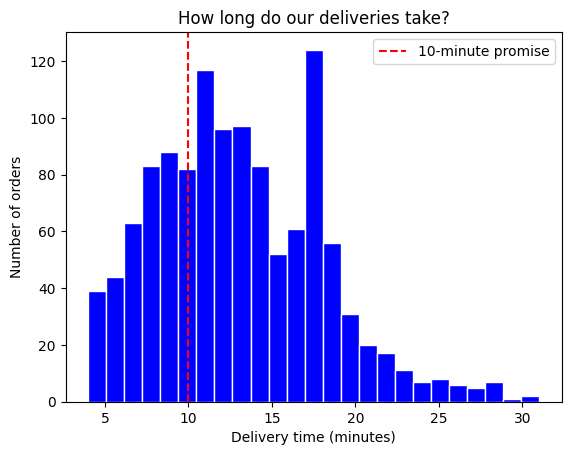

In [9]:
import matplotlib.pyplot as plt
plt.hist(df["Delivery_Time_Min"], bins=25, color="blue", edgecolor="white")
plt.axvline(10, color="red", linestyle="--", label="10-minute promise")
plt.title("How long do our deliveries take?")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Number of orders")
plt.legend()
plt.show()

Which product category brings the most sales

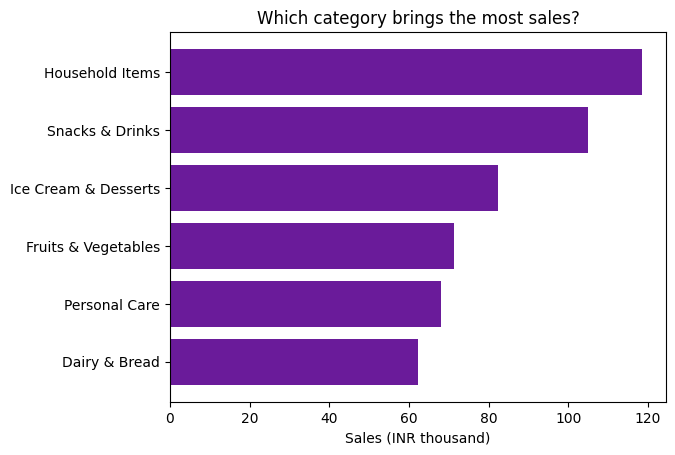

In [10]:
# Calculate total sales category-wise
category_sales = df.groupby("Category")["Order_Value"].sum().sort_values()

# Create bar chart
plt.barh(category_sales.index, category_sales.values / 1000, color="#6A1B9A")

# Add chart title
plt.title("Which category brings the most sales?")

# Add X-axis label
plt.xlabel("Sales (INR thousand)")

# Display chart
plt.show()

Are orders growing week by week

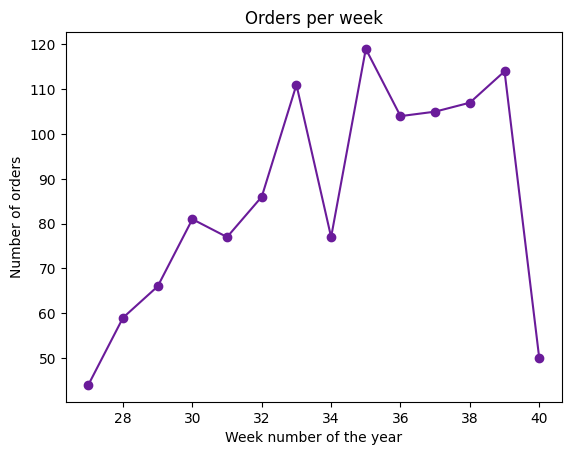

In [12]:
weekly_orders = df.groupby("Week")["Order_ID"].count()

plt.plot(weekly_orders.index, weekly_orders.values, marker="o", color="#6A1B9A")
plt.title("Orders per week")
plt.xlabel("Week number of the year")
plt.ylabel("Number of orders")
plt.show()

AREA PLOT-
which part of the day builds our weekly sales?

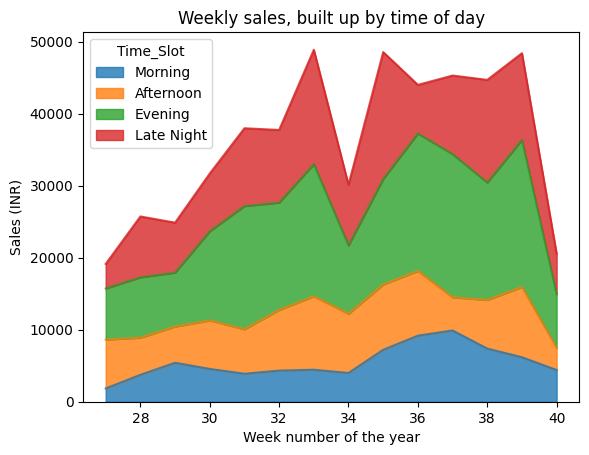

In [13]:
week_slot = df.pivot_table(index="Week", columns="Time_Slot", values="Order_Value", aggfunc="sum")[slot_order]

week_slot.plot(kind="area", alpha=0.8)
plt.title("Weekly sales, built up by time of day")
plt.xlabel("Week number of the year")
plt.ylabel("Sales (INR)")
plt.show()

Does a longer distance mean a slower delivery, and does a slow delivery mean a lower rating

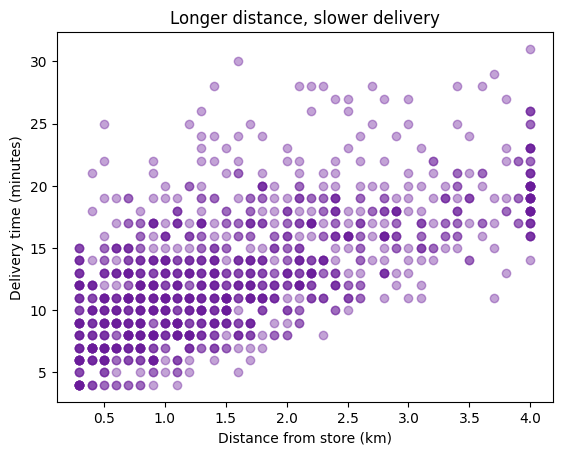

In [14]:
plt.scatter(df["Distance_KM"], df["Delivery_Time_Min"], alpha=0.4, color="#6A1B9A")
plt.title("Longer distance, slower delivery")
plt.xlabel("Distance from store (km)")
plt.ylabel("Delivery time (minutes)")
plt.show()

Scatter Plot

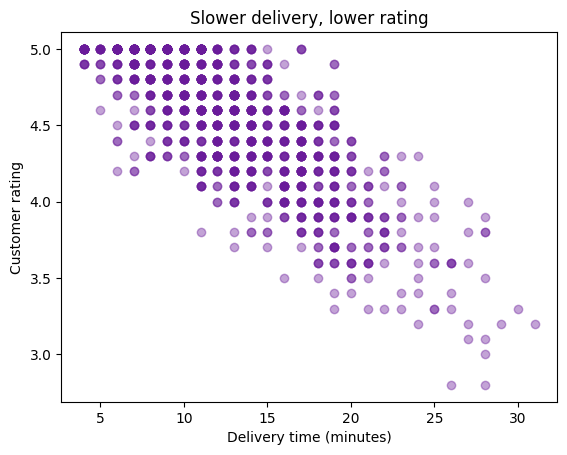

In [15]:
plt.scatter(df["Delivery_Time_Min"], df["Customer_Rating"], alpha=0.4, color="#6A1B9A")
plt.title("Slower delivery, lower rating")
plt.xlabel("Delivery time (minutes)")
plt.ylabel("Customer rating")
plt.show()

QUIVER PLOT

In [16]:
means = df.groupby(["State", "Weather"])[["Delivery_Time_Min", "Customer_Rating"]].mean().reset_index()

clear = means[means["Weather"] == "Clear"].set_index("State")
rain  = means[means["Weather"] == "Rain"].set_index("State")

x  = clear["Delivery_Time_Min"]                          # arrow starts here (clear weather)
y  = clear["Customer_Rating"]
dx = rain["Delivery_Time_Min"] - clear["Delivery_Time_Min"]   # how far rain moves it
dy = rain["Customer_Rating"] - clear["Customer_Rating"]

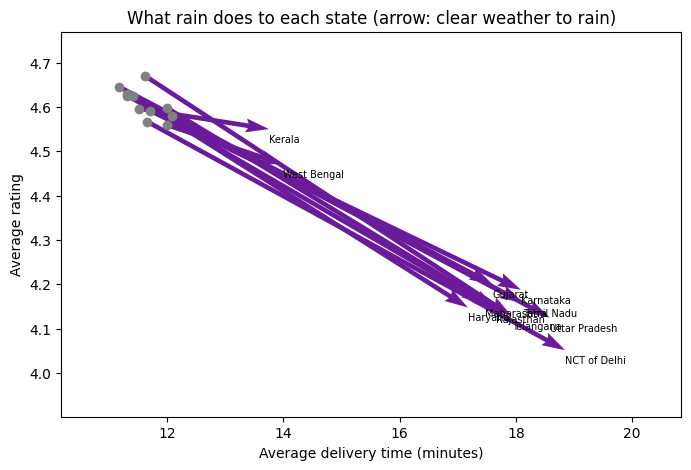

In [17]:
plt.figure(figsize=(8, 5))
plt.quiver(x, y, dx, dy, angles="xy", scale_units="xy", scale=1, color="#6A1B9A")
plt.scatter(x, y, color="grey")

for name in clear.index:
    plt.text(x[name] + dx[name], y[name] + dy[name] - 0.03, name, fontsize=7)   # label at the arrow tip

plt.xlim(x.min() - 1, (x + dx).max() + 2)
plt.ylim((y + dy).min() - 0.15, y.max() + 0.1)
plt.title("What rain does to each state (arrow: clear weather to rain)")
plt.xlabel("Average delivery time (minutes)")
plt.ylabel("Average rating")
plt.show()

CONTOUR PLOT/2D PLOT| STEP 1: Developing metrics

In [18]:

# A tiny example first
distance = np.array([1, 2, 3])
basket   = np.array([5, 10])

D, B = np.meshgrid(distance, basket)

print(D)
print(B)

[[1 2 3]
 [1 2 3]]
[[ 5  5  5]
 [10 10 10]]


STEP 2: Dividing metrics

In [19]:
dist_values   = np.linspace(0.3, 4, 40)     # 40 distances, 0.3 to 4 km
basket_values = np.linspace(1, 12, 40)      # 40 basket sizes, 1 to 12 items

D, B = np.meshgrid(dist_values, basket_values)

print("Number of what-if cases:", D.size)

Number of what-if cases: 1600


STEP 3: Linear regression- Prediction

In [20]:
# A simple formula from our data: delivery time from distance and basket size

from sklearn.linear_model import LinearRegression

formula = LinearRegression().fit(
    df[["Distance_KM", "Basket_Size"]],
    df["Delivery_Time_Min"]
)

print("Each extra km adds about", round(formula.coef_[0], 1), "minutes")
print("Each extra item adds about", round(formula.coef_[1], 2), "minutes")

Each extra km adds about 3.1 minutes
Each extra item adds about 0.31 minutes


STEP 4: What-if case

In [21]:
# Fill every what-if case with the expected delivery time
cases = pd.DataFrame({
    "Distance_KM": D.ravel(),
    "Basket_Size": B.ravel()
})

T = formula.predict(cases).reshape(D.shape)

How far can a store deliver, for a given basketand still keep the 10 minute promise

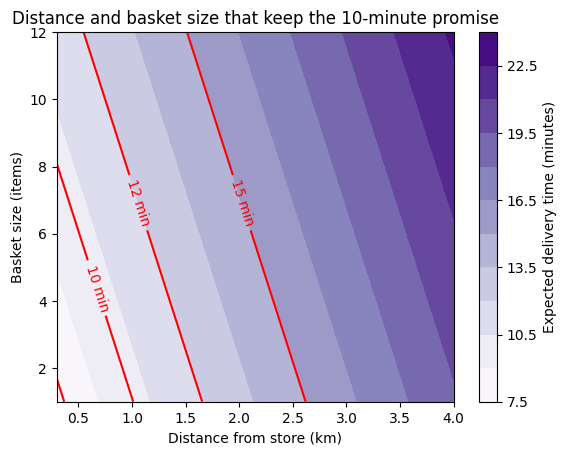

In [22]:
plt.contourf(D, B, T, levels=10, cmap="Purples")
plt.colorbar(label="Expected delivery time (minutes)")

lines = plt.contour(D, B, T, levels=[8, 10, 12, 15], colors="red")
plt.clabel(lines, fmt="%d min")

plt.title("Distance and basket size that keep the 10-minute promise")
plt.xlabel("Distance from store (km)")
plt.ylabel("Basket size (items)")
plt.show()